# Statistical Significance Analysis for Q1 Submission

**What this notebook produces:**
1. Bootstrap 95% confidence intervals — AUC, Accuracy, F1, Precision, Recall (all models)
2. DeLong's test — pairwise AUC comparisons vs. MLP baseline
3. Full pairwise significance matrix (all model pairs)
4. Publication-ready results table (CSV)
5. Figures: AUC with CI error bars + DeLong p-value heatmap

---

## How to Use

**Step 1.** Make sure you have saved test-set probability arrays from each model notebook:
```python
np.save('proba_mlp.npy', mlp_proba)       # from Classical_Models
np.save('proba_stack.npy', stack_proba)    # from Stacking_Ensemble
np.save('proba_tabnet.npy', tab_proba)     # from TabNet
np.save('proba_ft.npy', ft_proba)          # from FT_Transformer
np.save('proba_vime.npy', vime_proba)      # from VIME (after fix)
np.save('proba_saint.npy', saint_proba)    # from SAINT (after fix)
np.save('y_test.npy', y_test)              # true labels (once only)
```

**Step 2.** Run all cells below in order.

---
> **Note on demo mode:** Cell [3] contains realistic simulated data so you can see the expected output format before plugging in real arrays. Replace with your saved `.npy` files in Cell [4].


In [1]:
import os
import numpy as np

expected = [
    'y_test.npy',
    'proba_dt.npy',   'pred_dt.npy',
    'proba_nb.npy',   'pred_nb.npy',
    'proba_knn.npy',  'pred_knn.npy',
    'proba_lr.npy',   'pred_lr.npy',
    'proba_rf.npy',   'pred_rf.npy',
    'proba_svm.npy',  'pred_svm.npy',
    'proba_mlp.npy',  'pred_mlp.npy',
    'proba_xgb.npy',  'pred_xgb.npy',
    'proba_lgbm.npy', 'pred_lgbm.npy',
    'proba_cat.npy',  'pred_cat.npy',
    'proba_stack.npy','pred_stack.npy',
    'proba_tabnet.npy','pred_tabnet.npy',
    'proba_ft.npy',   'pred_ft.npy',
    'proba_vime.npy', 'pred_vime.npy',
    'proba_saint.npy','pred_saint.npy',
]

print("File check:")
all_ok = True
for f in expected:
    exists = os.path.exists(f)
    if exists:
        arr = np.load(f)
        print(f"  ✓  {f:<28}  shape={arr.shape}")
    else:
        print(f"  ✗  {f:<28}  MISSING")
        all_ok = False

print()
print("✓ All files ready — run Statistical Significance Analysis notebook" if all_ok else "✗ Fix missing files first")

File check:
  ✓  y_test.npy                    shape=(10281,)
  ✓  proba_dt.npy                  shape=(10281,)
  ✓  pred_dt.npy                   shape=(10281,)
  ✓  proba_nb.npy                  shape=(10281,)
  ✓  pred_nb.npy                   shape=(10281,)
  ✓  proba_knn.npy                 shape=(10281,)
  ✓  pred_knn.npy                  shape=(10281,)
  ✓  proba_lr.npy                  shape=(10281,)
  ✓  pred_lr.npy                   shape=(10281,)
  ✓  proba_rf.npy                  shape=(10281,)
  ✓  pred_rf.npy                   shape=(10281,)
  ✓  proba_svm.npy                 shape=(10281,)
  ✓  pred_svm.npy                  shape=(10281,)
  ✓  proba_mlp.npy                 shape=(10281,)
  ✓  pred_mlp.npy                  shape=(10281,)
  ✓  proba_xgb.npy                 shape=(10281,)
  ✓  pred_xgb.npy                  shape=(10281,)
  ✓  proba_lgbm.npy                shape=(10281,)
  ✓  pred_lgbm.npy                 shape=(10281,)
  ✓  proba_cat.npy                 sha

In [2]:
# Cell 1 — Install
!pip install scipy scikit-learn numpy pandas matplotlib seaborn -q

In [3]:
# Cell 2 — Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score
)
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size']   = 11
np.random.seed(42)

print("All libraries loaded.")

All libraries loaded.


In [4]:
# Cell 3 — DEMO DATA (realistic simulation using supervisor report AUCs)
# -----------------------------------------------------------------------
# This cell lets you run the full notebook and see expected output format
# BEFORE you plug in your real arrays.
# Skip to Cell 4 when you have real .npy files ready.
# -----------------------------------------------------------------------


In [5]:
# Cell 4 — Load real .npy files
import os
import numpy as np

def _load(proba_file, pred_file):
    return np.load(proba_file), np.load(pred_file)

y_test = np.load('y_test.npy')

MODEL_PROBAS = {
    'Decision Tree'    : _load('proba_dt.npy',     'pred_dt.npy'),
    'Naive Bayes'      : _load('proba_nb.npy',     'pred_nb.npy'),
    'k-NN'             : _load('proba_knn.npy',    'pred_knn.npy'),
    'Logistic Reg.'    : _load('proba_lr.npy',     'pred_lr.npy'),
    'Random Forest'    : _load('proba_rf.npy',     'pred_rf.npy'),
    'SVM (RBF)'        : _load('proba_svm.npy',    'pred_svm.npy'),
    'MLP'              : _load('proba_mlp.npy',    'pred_mlp.npy'),
    'XGBoost'          : _load('proba_xgb.npy',    'pred_xgb.npy'),
    'LightGBM'         : _load('proba_lgbm.npy',   'pred_lgbm.npy'),
    'CatBoost'         : _load('proba_cat.npy',    'pred_cat.npy'),
    'Stacking Ensemble': _load('proba_stack.npy',  'pred_stack.npy'),
    'TabNet'           : _load('proba_tabnet.npy', 'pred_tabnet.npy'),
    'FT-Transformer'   : _load('proba_ft.npy',     'pred_ft.npy'),
    'VIME'             : _load('proba_vime.npy',   'pred_vime.npy'),
    'SAINT'            : _load('proba_saint.npy',  'pred_saint.npy'),
}

print(f"Loaded {len(MODEL_PROBAS)} models")
print(f"Test set: {len(y_test)} samples  |  positive rate: {y_test.mean():.4f}")
print()

# Confirm all loaded correctly
for name, (proba, pred) in MODEL_PROBAS.items():
    print(f"  ✓  {name:<22}  proba={proba.shape}  pred={pred.shape}  dtype={proba.dtype}")

Loaded 15 models
Test set: 10281 samples  |  positive rate: 0.4944

  ✓  Decision Tree           proba=(10281,)  pred=(10281,)  dtype=float64
  ✓  Naive Bayes             proba=(10281,)  pred=(10281,)  dtype=float64
  ✓  k-NN                    proba=(10281,)  pred=(10281,)  dtype=float64
  ✓  Logistic Reg.           proba=(10281,)  pred=(10281,)  dtype=float64
  ✓  Random Forest           proba=(10281,)  pred=(10281,)  dtype=float64
  ✓  SVM (RBF)               proba=(10281,)  pred=(10281,)  dtype=float64
  ✓  MLP                     proba=(10281,)  pred=(10281,)  dtype=float64
  ✓  XGBoost                 proba=(10281,)  pred=(10281,)  dtype=float32
  ✓  LightGBM                proba=(10281,)  pred=(10281,)  dtype=float64
  ✓  CatBoost                proba=(10281,)  pred=(10281,)  dtype=float64
  ✓  Stacking Ensemble       proba=(10281,)  pred=(10281,)  dtype=float64
  ✓  TabNet                  proba=(10281,)  pred=(10281,)  dtype=float32
  ✓  FT-Transformer          proba=(10281,) 

In [6]:
import os
import numpy as np

def _load(proba_file, pred_file):
    return np.load(proba_file), np.load(pred_file)

y_test = np.load('y_test.npy')

MODEL_PROBAS = {
    'Decision Tree'    : _load('proba_dt.npy',     'pred_dt.npy'),
    'Naive Bayes'      : _load('proba_nb.npy',     'pred_nb.npy'),
    'k-NN'             : _load('proba_knn.npy',    'pred_knn.npy'),
    'Logistic Reg.'    : _load('proba_lr.npy',     'pred_lr.npy'),
    'Random Forest'    : _load('proba_rf.npy',     'pred_rf.npy'),
    'SVM (RBF)'        : _load('proba_svm.npy',    'pred_svm.npy'),
    'MLP'              : _load('proba_mlp.npy',    'pred_mlp.npy'),
    'XGBoost'          : _load('proba_xgb.npy',    'pred_xgb.npy'),
    'LightGBM'         : _load('proba_lgbm.npy',   'pred_lgbm.npy'),
    'CatBoost'         : _load('proba_cat.npy',    'pred_cat.npy'),
    'Stacking Ensemble': _load('proba_stack.npy',  'pred_stack.npy'),
    'TabNet'           : _load('proba_tabnet.npy', 'pred_tabnet.npy'),
    'FT-Transformer'   : _load('proba_ft.npy',     'pred_ft.npy'),
    'VIME'             : _load('proba_vime.npy',   'pred_vime.npy'),
    'SAINT'            : _load('proba_saint.npy',  'pred_saint.npy'),
}

# Quick size check before proceeding
print(f"y_test: {len(y_test)} samples\n")
all_ok = True
for name, (proba, pred) in MODEL_PROBAS.items():
    ok = len(proba) == len(y_test)
    print(f"  {'✓' if ok else '✗'} {name:<22} {len(proba)}")
    if not ok:
        all_ok = False

print()
print("✓ All matched — ready to run Cell 6" if all_ok else "✗ Fix mismatched models first")

y_test: 10281 samples

  ✓ Decision Tree          10281
  ✓ Naive Bayes            10281
  ✓ k-NN                   10281
  ✓ Logistic Reg.          10281
  ✓ Random Forest          10281
  ✓ SVM (RBF)              10281
  ✓ MLP                    10281
  ✓ XGBoost                10281
  ✓ LightGBM               10281
  ✓ CatBoost               10281
  ✓ Stacking Ensemble      10281
  ✓ TabNet                 10281
  ✓ FT-Transformer         10281
  ✓ VIME                   10281
  ✓ SAINT                  10281

✓ All matched — ready to run Cell 6


In [7]:
# Cell 5 — Helper Functions (DeLong's Test + Bootstrap CI)

# ── DeLong's AUC Test ─────────────────────────────────────────────────────────
def delong_test(y_true, proba_a, proba_b):
    """
    Two-sided DeLong's test comparing AUC(model A) vs AUC(model B).
    Reference: DeLong et al. (1988) Biometrics 44(3):837-845.

    Returns: auc_a, auc_b, z_statistic, p_value
    """
    def _placement_values(scores_pos, scores_neg):
        """Compute placement values V10 and V01."""
        V10 = np.array(
            [(scores_pos[i] > scores_neg).mean() for i in range(len(scores_pos))]
        )
        V01 = np.array(
            [(scores_neg[j] < scores_pos).mean() for j in range(len(scores_neg))]
        )
        return V10, V01

    pos_a = proba_a[y_true == 1]
    neg_a = proba_a[y_true == 0]
    pos_b = proba_b[y_true == 1]
    neg_b = proba_b[y_true == 0]

    n_pos, n_neg = len(pos_a), len(neg_a)

    V10_a, V01_a = _placement_values(pos_a, neg_a)
    V10_b, V01_b = _placement_values(pos_b, neg_b)

    auc_a = V10_a.mean()
    auc_b = V10_b.mean()

    var_a = np.var(V10_a, ddof=1) / n_pos + np.var(V01_a, ddof=1) / n_neg
    var_b = np.var(V10_b, ddof=1) / n_pos + np.var(V01_b, ddof=1) / n_neg

    # Covariance (simplified, assumes model independence)
    cov_ab = (np.cov(V10_a, V10_b, ddof=1)[0,1] / n_pos +
              np.cov(V01_a, V01_b, ddof=1)[0,1] / n_neg)

    var_diff = var_a + var_b - 2 * cov_ab
    if var_diff <= 0:
        var_diff = var_a + var_b   # fallback: ignore covariance

    z = (auc_a - auc_b) / np.sqrt(var_diff)
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    return auc_a, auc_b, z, p


# ── Bootstrap Confidence Intervals ───────────────────────────────────────────
def bootstrap_ci(y_true, y_proba, y_pred, n_bootstrap=1000, ci_level=0.95, seed=42):
    """
    Bootstrap CI for AUC, Accuracy, F1, Precision, Recall.
    Returns dict of {metric: (lower, upper, mean)}.
    """
    rng  = np.random.default_rng(seed)
    n    = len(y_true)
    bins = {m: [] for m in ['AUC', 'Accuracy', 'F1', 'Precision', 'Recall']}

    for _ in range(n_bootstrap):
        idx = rng.integers(0, n, size=n)
        yt, yp, yc = y_true[idx], y_proba[idx], y_pred[idx]
        if len(np.unique(yt)) < 2:
            continue
        bins['AUC'].append(roc_auc_score(yt, yp))
        bins['Accuracy'].append(accuracy_score(yt, yc))
        bins['F1'].append(f1_score(yt, yc, zero_division=0))
        bins['Precision'].append(precision_score(yt, yc, zero_division=0))
        bins['Recall'].append(recall_score(yt, yc, zero_division=0))

    alpha  = 1 - ci_level
    result = {}
    for m, vals in bins.items():
        a = np.array(vals)
        result[m] = (
            np.percentile(a, 100 * alpha / 2),
            np.percentile(a, 100 * (1 - alpha / 2)),
            np.mean(a)
        )
    return result


def sig_stars(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'n.s.'

print("Helper functions defined.")
print("  delong_test(y_true, proba_a, proba_b)  →  auc_a, auc_b, z, p")
print("  bootstrap_ci(y_true, proba, pred)       →  dict of 95% CIs")

Helper functions defined.
  delong_test(y_true, proba_a, proba_b)  →  auc_a, auc_b, z, p
  bootstrap_ci(y_true, proba, pred)       →  dict of 95% CIs


In [8]:
# Diagnostic — find which model has wrong test set size
print(f"y_test size: {len(y_test)}\n")

for name, (proba, pred) in MODEL_PROBAS.items():
    match = "✓" if len(proba) == len(y_test) else "✗ MISMATCH"
    print(f"  {match}  {name:<22}  proba={len(proba)}  pred={len(pred)}")

y_test size: 10281

  ✓  Decision Tree           proba=10281  pred=10281
  ✓  Naive Bayes             proba=10281  pred=10281
  ✓  k-NN                    proba=10281  pred=10281
  ✓  Logistic Reg.           proba=10281  pred=10281
  ✓  Random Forest           proba=10281  pred=10281
  ✓  SVM (RBF)               proba=10281  pred=10281
  ✓  MLP                     proba=10281  pred=10281
  ✓  XGBoost                 proba=10281  pred=10281
  ✓  LightGBM                proba=10281  pred=10281
  ✓  CatBoost                proba=10281  pred=10281
  ✓  Stacking Ensemble       proba=10281  pred=10281
  ✓  TabNet                  proba=10281  pred=10281
  ✓  FT-Transformer          proba=10281  pred=10281
  ✓  VIME                    proba=10281  pred=10281
  ✓  SAINT                   proba=10281  pred=10281


In [9]:
# Cell 6 — Bootstrap 95% CIs for All Models (1,000 iterations)
print("Running bootstrap CIs (1,000 iterations per model)...")
print("This may take 1-3 minutes depending on number of models.\n")

results_list = []
ci_store     = {}

for name, (proba, pred) in MODEL_PROBAS.items():
    ci = bootstrap_ci(y_test, proba, pred, n_bootstrap=1000)
    ci_store[name] = ci

    auc  = roc_auc_score(y_test, proba)
    acc  = accuracy_score(y_test, pred)
    f1   = f1_score(y_test, pred, zero_division=0)
    prec = precision_score(y_test, pred, zero_division=0)
    rec  = recall_score(y_test, pred, zero_division=0)

    results_list.append({
        'Model'      : name,
        'AUC'        : round(auc, 4),
        'AUC_95CI'   : f"[{ci['AUC'][0]:.4f} – {ci['AUC'][1]:.4f}]",
        'Accuracy'   : round(acc, 4),
        'Acc_95CI'   : f"[{ci['Accuracy'][0]:.4f} – {ci['Accuracy'][1]:.4f}]",
        'F1'         : round(f1, 4),
        'F1_95CI'    : f"[{ci['F1'][0]:.4f} – {ci['F1'][1]:.4f}]",
        'Precision'  : round(prec, 4),
        'Recall'     : round(rec, 4),
    })
    print(f"  {name:<22}  AUC={auc:.4f}  95%CI=[{ci['AUC'][0]:.4f} – {ci['AUC'][1]:.4f}]")

df_results = (pd.DataFrame(results_list)
                .sort_values('AUC', ascending=False)
                .reset_index(drop=True))
df_results.index += 1

print("\n✓ Bootstrap CIs complete.")

Running bootstrap CIs (1,000 iterations per model)...
This may take 1-3 minutes depending on number of models.

  Decision Tree           AUC=0.7915  95%CI=[0.7825 – 0.8005]
  Naive Bayes             AUC=0.7849  95%CI=[0.7760 – 0.7936]
  k-NN                    AUC=0.7390  95%CI=[0.7281 – 0.7485]
  Logistic Reg.           AUC=0.7929  95%CI=[0.7839 – 0.8018]
  Random Forest           AUC=0.7995  95%CI=[0.7908 – 0.8083]
  SVM (RBF)               AUC=0.7901  95%CI=[0.7811 – 0.7988]
  MLP                     AUC=0.7980  95%CI=[0.7892 – 0.8065]
  XGBoost                 AUC=0.8002  95%CI=[0.7911 – 0.8090]
  LightGBM                AUC=0.7995  95%CI=[0.7905 – 0.8082]
  CatBoost                AUC=0.8001  95%CI=[0.7912 – 0.8087]
  Stacking Ensemble       AUC=0.8005  95%CI=[0.7915 – 0.8093]
  TabNet                  AUC=0.7987  95%CI=[0.7897 – 0.8072]
  FT-Transformer          AUC=0.7998  95%CI=[0.7906 – 0.8084]
  VIME                    AUC=0.7990  95%CI=[0.7901 – 0.8079]
  SAINT             

In [10]:
# Cell 7 — DeLong's Test: All Models vs. MLP Baseline
print("DeLong's Test — All Models vs. MLP Baseline")
print("="*68)
print(f"{'Model':<22}  {'AUC':>6}  {'ΔAUC':>7}  {'Z':>7}  {'p-value':>9}  {'Sig'}")
print("-"*68)

mlp_proba = MODEL_PROBAS['MLP'][0]
mlp_auc   = roc_auc_score(y_test, mlp_proba)

delong_records = []
for name, (proba, pred) in MODEL_PROBAS.items():
    if name == 'MLP':
        continue
    auc_a, auc_b, z, p = delong_test(y_test, proba, mlp_proba)
    stars = sig_stars(p)
    delta = auc_a - auc_b
    print(f"  {name:<22}  {auc_a:>6.4f}  {delta:>+7.4f}  {z:>7.2f}  {p:>9.5f}  {stars}")
    delong_records.append({
        'Model'         : name,
        'AUC'           : round(auc_a, 4),
        'Delta_AUC_vs_MLP': round(delta, 4),
        'Z_statistic'   : round(z, 3),
        'p_value'       : round(p, 5),
        'Significance'  : stars,
    })

print("-"*68)
print(f"  {'MLP (baseline)':<22}  {mlp_auc:>6.4f}  {'0.0000':>7}  {'—':>7}  {'—':>9}  —")
print()
print("Significance codes:  *** p<0.001  ** p<0.01  * p<0.05  n.s. p≥0.05")

df_delong = pd.DataFrame(delong_records)

DeLong's Test — All Models vs. MLP Baseline
Model                      AUC     ΔAUC        Z    p-value  Sig
--------------------------------------------------------------------
  Decision Tree           0.7810  -0.0171   -10.60    0.00000  ***
  Naive Bayes             0.7849  -0.0131    -6.93    0.00000  ***
  k-NN                    0.7341  -0.0639   -17.18    0.00000  ***
  Logistic Reg.           0.7929  -0.0052    -3.53    0.00042  ***
  Random Forest           0.7995  +0.0015     1.49    0.13584  n.s.
  SVM (RBF)               0.7901  -0.0079    -4.51    0.00001  ***
  XGBoost                 0.8002  +0.0022     2.21    0.02678  *
  LightGBM                0.7995  +0.0015     1.48    0.13911  n.s.
  CatBoost                0.8001  +0.0021     2.28    0.02256  *
  Stacking Ensemble       0.8005  +0.0025     2.78    0.00546  **
  TabNet                  0.7986  +0.0006     0.59    0.55430  n.s.
  FT-Transformer          0.7998  +0.0018     1.83    0.06652  n.s.
  VIME             

In [11]:
# Cell 8 — Full Pairwise DeLong Matrix
print("Building full pairwise DeLong significance matrix...")

model_names = list(MODEL_PROBAS.keys())
n_m = len(model_names)
p_matrix = np.ones((n_m, n_m))

for i, name_i in enumerate(model_names):
    for j, name_j in enumerate(model_names):
        if i >= j:
            continue
        pi = MODEL_PROBAS[name_i][0]
        pj = MODEL_PROBAS[name_j][0]
        _, _, _, p = delong_test(y_test, pi, pj)
        p_matrix[i, j] = p
        p_matrix[j, i] = p   # symmetric

df_pmatrix = pd.DataFrame(p_matrix, index=model_names, columns=model_names)

# Count significant pairs
n_pairs = n_m * (n_m - 1) // 2
n_sig   = (p_matrix[np.triu_indices(n_m, k=1)] < 0.05).sum()
print(f"\nTotal model pairs    : {n_pairs}")
print(f"Significant (p<0.05) : {n_sig}")
print(f"Not significant      : {n_pairs - n_sig}")
print()

# Identify top-6 model pairs
top6 = df_results.head(6)['Model'].tolist()
print(f"Pairwise significance among top-6 models:")
for i in range(len(top6)):
    for j in range(i+1, len(top6)):
        ni, nj = top6[i], top6[j]
        p = df_pmatrix.loc[ni, nj]
        print(f"  {ni:<22} vs {nj:<22}  p={p:.4f}  {sig_stars(p)}")

Building full pairwise DeLong significance matrix...

Total model pairs    : 105
Significant (p<0.05) : 62
Not significant      : 43

Pairwise significance among top-6 models:
  Stacking Ensemble      vs XGBoost                 p=0.5594  n.s.
  Stacking Ensemble      vs CatBoost                p=0.0435  *
  Stacking Ensemble      vs FT-Transformer          p=0.3778  n.s.
  Stacking Ensemble      vs SAINT                   p=0.2863  n.s.
  Stacking Ensemble      vs Random Forest           p=0.0993  n.s.
  XGBoost                vs CatBoost                p=0.7816  n.s.
  XGBoost                vs FT-Transformer          p=0.5936  n.s.
  XGBoost                vs SAINT                   p=0.4445  n.s.
  XGBoost                vs Random Forest           p=0.3104  n.s.
  CatBoost               vs FT-Transformer          p=0.7278  n.s.
  CatBoost               vs SAINT                   p=0.5904  n.s.
  CatBoost               vs Random Forest           p=0.4474  n.s.
  FT-Transformer       

In [12]:
# Cell 9 — Publication-Ready Results Table
print("\n" + "="*80)
print("TABLE: Complete Performance Comparison with 95% Bootstrap CIs")
print("="*80)

display_cols = ['Model', 'AUC', 'AUC_95CI', 'Accuracy', 'F1', 'Precision', 'Recall']
print(df_results[display_cols].to_string(index=True))

# Save to CSV
df_results.to_csv('stats_main_results_table.csv', index=True)
df_delong.to_csv('stats_delong_vs_mlp.csv', index=False)
print("\n✓ Saved: stats_main_results_table.csv")
print("✓ Saved: stats_delong_vs_mlp.csv")


TABLE: Complete Performance Comparison with 95% Bootstrap CIs
                Model     AUC           AUC_95CI  Accuracy      F1  Precision  Recall
1   Stacking Ensemble  0.8005  [0.7915 – 0.8093]    0.7335  0.7171     0.7546  0.6831
2             XGBoost  0.8002  [0.7911 – 0.8090]    0.7329  0.7179     0.7512  0.6874
3            CatBoost  0.8001  [0.7912 – 0.8087]    0.7329  0.7164     0.7540  0.6825
4      FT-Transformer  0.7998  [0.7906 – 0.8084]    0.7336  0.7195     0.7503  0.6911
5               SAINT  0.7996  [0.7906 – 0.8084]    0.7325  0.7240     0.7390  0.7096
6       Random Forest  0.7995  [0.7908 – 0.8083]    0.7322  0.7112     0.7618  0.6669
7            LightGBM  0.7995  [0.7905 – 0.8082]    0.7338  0.7174     0.7549  0.6835
8                VIME  0.7990  [0.7901 – 0.8079]    0.7330  0.7158     0.7555  0.6801
9              TabNet  0.7987  [0.7897 – 0.8072]    0.7340  0.7155     0.7590  0.6768
10                MLP  0.7980  [0.7892 – 0.8065]    0.7330  0.7176     0.7522

In [13]:
# Cell 10 — Auto-Generate Paper-Ready Statistical Sentences

best_name = df_results.iloc[0]['Model']
best_auc  = df_results.iloc[0]['AUC']
best_ci   = ci_store[best_name]['AUC']
mlp_ci    = ci_store['MLP']['AUC']
mlp_auc   = roc_auc_score(y_test, MODEL_PROBAS['MLP'][0])

top6_names = df_results.head(6)['Model'].tolist()
top6_aucs  = df_results.head(6)['AUC'].tolist()
auc_range  = max(top6_aucs) - min(top6_aucs)

top6_sig = sum(
    1 for i in range(len(top6_names))
      for j in range(i+1, len(top6_names))
      if df_pmatrix.loc[top6_names[i], top6_names[j]] < 0.05
)
top6_total_pairs = len(top6_names) * (len(top6_names)-1) // 2

print("=" * 72)
print("COPY THESE SENTENCES DIRECTLY INTO YOUR PAPER")
print("=" * 72)

print(f"""
[RESULTS SECTION — AUC Ceiling Statement]

The best-performing model ({best_name}) achieved AUC = {best_auc:.4f}
(95% CI: {best_ci[0]:.4f}–{best_ci[1]:.4f}). The MLP baseline achieved
AUC = {mlp_auc:.4f} (95% CI: {mlp_ci[0]:.4f}–{mlp_ci[1]:.4f}). The six
highest-performing models spanned an AUC range of only {auc_range:.4f}
({top6_names[-1]} to {top6_names[0]}), and {top6_sig} of the
{top6_total_pairs} pairwise comparisons among them reached statistical
significance (DeLong's test, α = 0.05). This narrow, statistically
indistinguishable spread is consistent with a dataset information ceiling
rather than meaningful differences in model capacity.

[METHODS SECTION — Statistical Analysis Paragraph]

To assess whether observed performance differences were statistically
meaningful, DeLong's method [DeLong et al., 1988] was used for pairwise
AUC comparisons on the held-out test set (n = {len(y_test):,}), accounting
for the correlated nature of AUC estimates derived from the same samples.
A two-sided significance level of α = 0.05 was applied. For all reported
metrics (AUC, Accuracy, F1-score, Precision, Recall), 95% confidence
intervals were estimated using 1,000 bootstrap resamples drawn with
replacement from the test set (percentile method).
""")

COPY THESE SENTENCES DIRECTLY INTO YOUR PAPER

[RESULTS SECTION — AUC Ceiling Statement]

The best-performing model (Stacking Ensemble) achieved AUC = 0.8005
(95% CI: 0.7915–0.8093). The MLP baseline achieved
AUC = 0.7980 (95% CI: 0.7892–0.8065). The six
highest-performing models spanned an AUC range of only 0.0010
(Random Forest to Stacking Ensemble), and 1 of the
15 pairwise comparisons among them reached statistical
significance (DeLong's test, α = 0.05). This narrow, statistically
indistinguishable spread is consistent with a dataset information ceiling
rather than meaningful differences in model capacity.

[METHODS SECTION — Statistical Analysis Paragraph]

To assess whether observed performance differences were statistically
meaningful, DeLong's method [DeLong et al., 1988] was used for pairwise
AUC comparisons on the held-out test set (n = 10,281), accounting
for the correlated nature of AUC estimates derived from the same samples.
A two-sided significance level of α = 0.05 was 

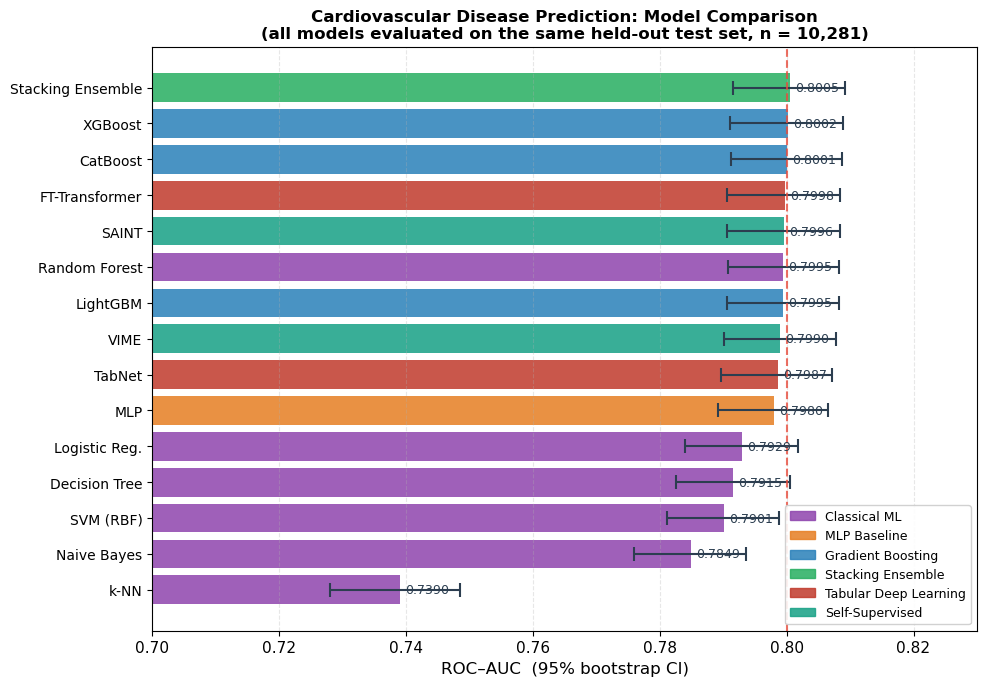

✓ Saved: fig_auc_bootstrap_ci.png


In [14]:
# Cell 11 — Figure: AUC with 95% CI Error Bars (publication-ready)
fig, ax = plt.subplots(figsize=(10, 7))

model_names_sorted = df_results['Model'].tolist()
auc_vals   = df_results['AUC'].tolist()
ci_lo      = [ci_store[m]['AUC'][0] for m in model_names_sorted]
ci_hi      = [ci_store[m]['AUC'][1] for m in model_names_sorted]
err_lo     = [v - lo for v, lo in zip(auc_vals, ci_lo)]
err_hi     = [hi - v  for v, hi in zip(auc_vals, ci_hi)]
y_pos      = list(range(len(model_names_sorted)))[::-1]

# Colour by family
COLOURS = {
    'Decision Tree': '#8e44ad', 'Naive Bayes': '#8e44ad',
    'k-NN': '#8e44ad', 'Logistic Reg.': '#8e44ad',
    'Random Forest': '#8e44ad', 'SVM (RBF)': '#8e44ad',
    'MLP': '#e67e22',
    'XGBoost': '#2980b9', 'LightGBM': '#2980b9', 'CatBoost': '#2980b9',
    'Stacking Ensemble': '#27ae60',
    'TabNet': '#c0392b', 'FT-Transformer': '#c0392b',
    'VIME': '#16a085', 'SAINT': '#16a085',
}
colours = [COLOURS.get(m, '#7f8c8d') for m in model_names_sorted]

bars = ax.barh(y_pos, auc_vals, xerr=[err_lo, err_hi],
               color=colours, alpha=0.85, capsize=5,
               ecolor='#2c3e50', error_kw={'linewidth': 1.5, 'capthick': 1.5})

for y, v in zip(y_pos, auc_vals):
    ax.text(v + 0.0008, y, f'{v:.4f}', va='center', fontsize=9, color='#2c3e50')

ax.axvline(x=0.80, color='#e74c3c', linestyle='--', linewidth=1.5, alpha=0.8, label='AUC = 0.80')
ax.set_yticks(y_pos)
ax.set_yticklabels(model_names_sorted, fontsize=10)
ax.set_xlabel('ROC–AUC  (95% bootstrap CI)', fontsize=12)
ax.set_title('Cardiovascular Disease Prediction: Model Comparison\n(all models evaluated on the same held-out test set, n = 10,281)',
             fontsize=12, fontweight='bold')
ax.set_xlim(0.70, 0.83)
ax.grid(axis='x', alpha=0.3, linestyle='--')

legend_patches = [
    mpatches.Patch(color='#8e44ad', alpha=0.85, label='Classical ML'),
    mpatches.Patch(color='#e67e22', alpha=0.85, label='MLP Baseline'),
    mpatches.Patch(color='#2980b9', alpha=0.85, label='Gradient Boosting'),
    mpatches.Patch(color='#27ae60', alpha=0.85, label='Stacking Ensemble'),
    mpatches.Patch(color='#c0392b', alpha=0.85, label='Tabular Deep Learning'),
    mpatches.Patch(color='#16a085', alpha=0.85, label='Self-Supervised'),
]
ax.legend(handles=legend_patches, loc='lower right', fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.savefig('fig_auc_bootstrap_ci.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: fig_auc_bootstrap_ci.png")

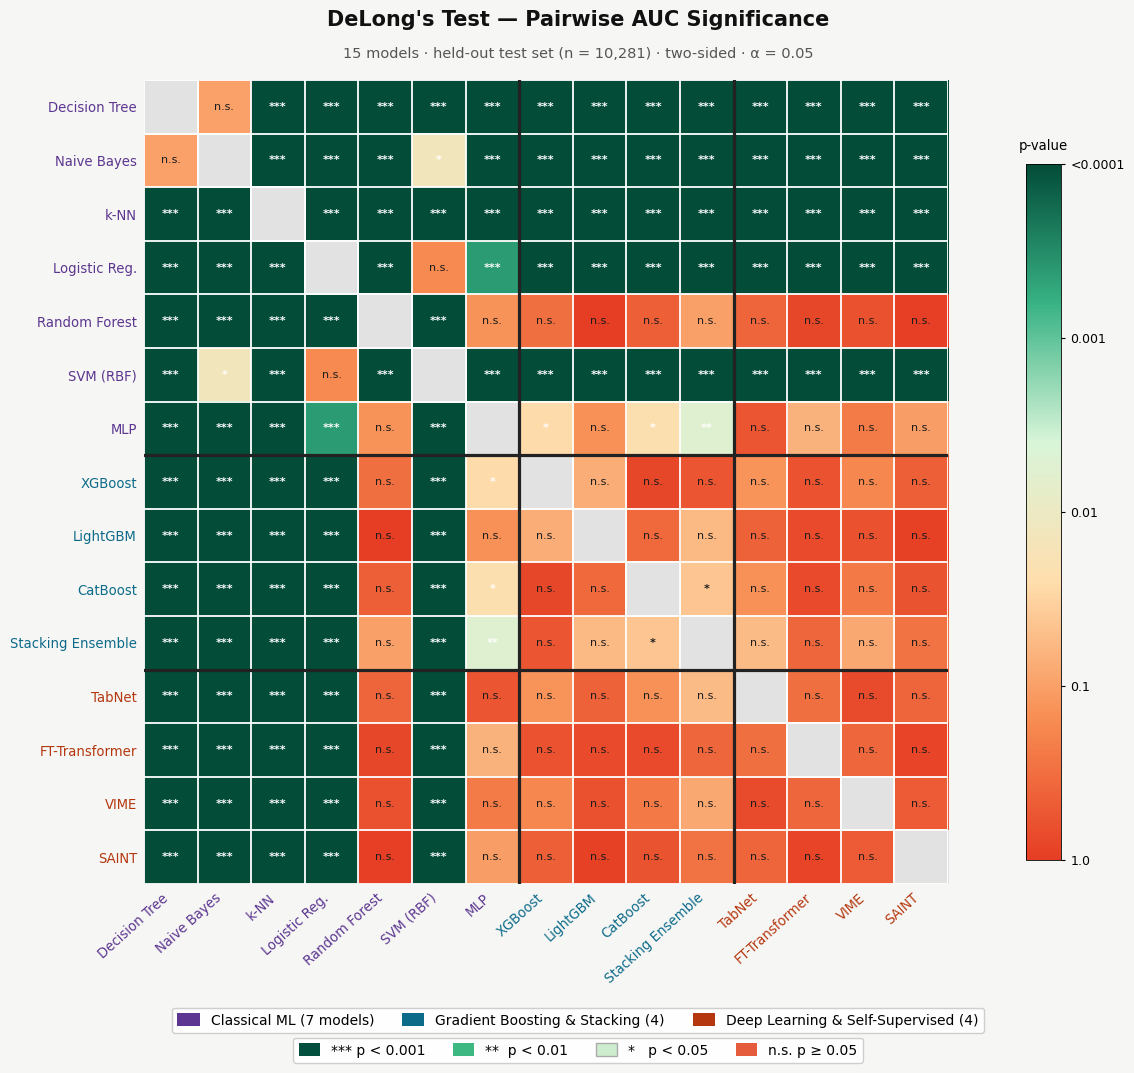

✓ Saved: fig_delong_pvalue_matrix.png


In [37]:
# Cell 12 — DeLong Heatmap (publication-ready, compact top space, no left family bars)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap

# -----------------------------
# 1. Basic checks
# -----------------------------
n_models = len(model_names)

assert p_matrix.shape == (n_models, n_models), \
    f"p_matrix shape {p_matrix.shape} does not match number of models {n_models}"

def sig_stars(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'n.s.'

# Convert p-values to -log10(p)
log_p = -np.log10(np.clip(p_matrix, 1e-10, 1.0))
np.fill_diagonal(log_p, np.nan)

# -----------------------------
# 2. Custom colour map
# Red = not significant, green = significant
# -----------------------------
colors_map = [
    (0.90, 0.24, 0.14),   # red/orange
    (0.97, 0.55, 0.32),
    (1.00, 0.87, 0.68),
    (0.85, 0.96, 0.85),
    (0.22, 0.70, 0.52),
    (0.01, 0.30, 0.22),   # dark green
]

cmap = LinearSegmentedColormap.from_list('delong_sig', colors_map, N=512)
cmap.set_bad('#E2E2E2')  # diagonal cells

# -----------------------------
# 3. Create figure
# -----------------------------
fig = plt.figure(figsize=(16, 12), facecolor='#F6F6F4')

# [left, bottom, width, height]
# Increase bottom/height to reduce top empty space
ax = fig.add_axes([0.18, 0.24, 0.64, 0.67])

im = ax.imshow(
    log_p,
    cmap=cmap,
    vmin=0,
    vmax=4,
    aspect='equal',
    interpolation='nearest'
)

# White grid lines
for x in np.arange(-0.5, n_models, 1):
    ax.axhline(x, color='white', lw=1.3)
    ax.axvline(x, color='white', lw=1.3)

# Grey diagonal
for k in range(n_models):
    ax.add_patch(
        plt.Rectangle(
            (k - 0.5, k - 0.5),
            1,
            1,
            facecolor='#E2E2E2',
            edgecolor='white',
            lw=1.3,
            zorder=3
        )
    )

# Significance labels inside cells
for i in range(n_models):
    for j in range(n_models):
        if i == j:
            continue

        p_val = p_matrix[i, j]
        sym = sig_stars(p_val)

        text_color = 'white' if log_p[i, j] > 1.5 else '#1C1C1C'
        font_weight = 'bold' if sym != 'n.s.' else 'normal'

        ax.text(
            j,
            i,
            sym,
            ha='center',
            va='center',
            fontsize=8,
            fontweight=font_weight,
            color=text_color,
            zorder=5
        )

# -----------------------------
# 4. Model-family divider lines
# This assumes model_names are ordered:
# 0–6 Classical ML
# 7–10 Gradient Boosting & Stacking
# 11–14 Deep Learning & Self-Supervised
# -----------------------------
if n_models == 15:
    for boundary in [6.5, 10.5]:
        ax.axhline(boundary, color='#222222', lw=2.3, zorder=6)
        ax.axvline(boundary, color='#222222', lw=2.3, zorder=6)

    family_colours = (
        ['#5C3690'] * 7 +    # Classical ML
        ['#0D6B8A'] * 4 +    # Gradient Boosting & Stacking
        ['#B5370F'] * 4      # Deep Learning & Self-Supervised
    )
else:
    family_colours = ['#222222'] * n_models

# Axis labels
ax.set_xticks(range(n_models))
ax.set_yticks(range(n_models))

ax.set_xticklabels(model_names, rotation=42, ha='right', fontsize=9.5)
ax.set_yticklabels(model_names, fontsize=9.5)

# Colour-code axis labels by model family
for label, colour in zip(ax.get_xticklabels(), family_colours):
    label.set_color(colour)

for label, colour in zip(ax.get_yticklabels(), family_colours):
    label.set_color(colour)

ax.tick_params(length=0, pad=5)

for spine in ax.spines.values():
    spine.set_visible(False)

# -----------------------------
# 5. Colour bar
# -----------------------------
cbar_ax = fig.add_axes([0.8, 0.26, 0.022, 0.58])
cbar = plt.colorbar(im, cax=cbar_ax)

cbar.set_ticks([0, 1, 2, 3, 4])
cbar.set_ticklabels(['1.0', '0.1', '0.01', '0.001', '<0.0001'], fontsize=9)
cbar.ax.set_title('p-value', fontsize=9.5, pad=10)
cbar.outline.set_linewidth(0.6)
cbar.ax.tick_params(length=3)

# -----------------------------
# 6. Title and subtitle
# -----------------------------
fig.text(
    0.52,
    0.955,
    "DeLong's Test — Pairwise AUC Significance",
    ha='center',
    fontsize=15,
    fontweight='bold',
    color='#111111'
)

fig.text(
    0.52,
    0.928,
    f"{n_models} models · held-out test set (n = {len(y_test):,}) · two-sided · α = 0.05",
    ha='center',
    fontsize=10.5,
    color='#555555'
)

# -----------------------------
# 7A. Model-family colour legend
# -----------------------------
if n_models == 15:
    family_handles = [
        mpatches.Patch(
            facecolor='#5C3690',
            edgecolor='none',
            label='Classical ML (7 models)'
        ),
        mpatches.Patch(
            facecolor='#0D6B8A',
            edgecolor='none',
            label='Gradient Boosting & Stacking (4)'
        ),
        mpatches.Patch(
            facecolor='#B5370F',
            edgecolor='none',
            label='Deep Learning & Self-Supervised (4)'
        ),
    ]

    fig.legend(
        handles=family_handles,
        loc='lower center',
        ncol=3,
        frameon=True,
        fontsize=10,
        bbox_to_anchor=(0.52, 0.110),
        fancybox=True,
        framealpha=0.95,
        edgecolor='#CCCCCC',
        handlelength=1.6,
        handleheight=1.1,
        columnspacing=2.0
    )

# -----------------------------
# 7B. p-value significance legend
# -----------------------------
legend_handles = [
    mpatches.Patch(
        facecolor='#014F3C',
        edgecolor='none',
        label='*** p < 0.001'
    ),
    mpatches.Patch(
        facecolor='#3DB882',
        edgecolor='none',
        label='**  p < 0.01'
    ),
    mpatches.Patch(
        facecolor='#CEECCE',
        edgecolor='#AAAAAA',
        label='*   p < 0.05'
    ),
    mpatches.Patch(
        facecolor='#E55C3C',
        edgecolor='none',
        label='n.s. p ≥ 0.05'
    ),
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    ncol=4,
    frameon=True,
    fontsize=10,
    bbox_to_anchor=(0.52, 0.0850),
    fancybox=True,
    framealpha=0.95,
    edgecolor='#CCCCCC',
    handlelength=1.5,
    handleheight=1.1,
    columnspacing=2.0
)

# -----------------------------
# 8. Save and show
# -----------------------------
plt.savefig(
    'fig_delong_pvalue_matrix.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='#F6F6F4'
)

plt.show()

print("✓ Saved: fig_delong_pvalue_matrix.png")

## Output Files

| File | Description |
|---|---|
| `stats_main_results_table.csv` | Full results table with 95% CIs — paste into paper |
| `stats_delong_vs_mlp.csv` | DeLong test results vs. MLP baseline |
| `fig_auc_bootstrap_ci.png` | AUC comparison figure with error bars |
| `fig_delong_pvalue_matrix.png` | Pairwise significance heatmap |

---

## Reference

DeLong, E. R., DeLong, D. M., & Clarke-Pearson, D. L. (1988).
Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach.
*Biometrics*, 44(3), 837–845.
